In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, cross_val_score
from catboost import CatBoostClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import precision_recall_curve, average_precision_score
pd.set_option('display.max_columns', None)

In [2]:
df1 = pd.read_csv('BankChurners.csv')
df_train = df1.copy()
df_train

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1,Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,0.000093,0.999910
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,0.000057,0.999940
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,0.000021,0.999980
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,0.000134,0.999870
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000,0.000022,0.999980
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10122,772366833,Existing Customer,50,M,2,Graduate,Single,$40K - $60K,Blue,40,3,2,3,4003.0,1851,2152.0,0.703,15476,117,0.857,0.462,0.000191,0.999810
10123,710638233,Attrited Customer,41,M,2,Unknown,Divorced,$40K - $60K,Blue,25,4,2,3,4277.0,2186,2091.0,0.804,8764,69,0.683,0.511,0.995270,0.004729
10124,716506083,Attrited Customer,44,F,1,High School,Married,Less than $40K,Blue,36,5,3,4,5409.0,0,5409.0,0.819,10291,60,0.818,0.000,0.997880,0.002118
10125,717406983,Attrited Customer,30,M,2,Graduate,Unknown,$40K - $60K,Blue,36,4,3,3,5281.0,0,5281.0,0.535,8395,62,0.722,0.000,0.996710,0.003294


In [3]:
df_train.columns 

Index(['CLIENTNUM', 'Attrition_Flag', 'Customer_Age', 'Gender',
       'Dependent_count', 'Education_Level', 'Marital_Status',
       'Income_Category', 'Card_Category', 'Months_on_book',
       'Total_Relationship_Count', 'Months_Inactive_12_mon',
       'Contacts_Count_12_mon', 'Credit_Limit', 'Total_Revolving_Bal',
       'Avg_Open_To_Buy', 'Total_Amt_Chng_Q4_Q1', 'Total_Trans_Amt',
       'Total_Trans_Ct', 'Total_Ct_Chng_Q4_Q1', 'Avg_Utilization_Ratio',
       'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1',
       'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2'],
      dtype='object')

In [4]:
colla = ['Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_1',
       'Naive_Bayes_Classifier_Attrition_Flag_Card_Category_Contacts_Count_12_mon_Dependent_count_Education_Level_Months_Inactive_12_mon_2', 'CLIENTNUM'] 
df_train.drop(colla, axis = 1, inplace = True)

In [5]:
df_train

,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061
1,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105
2,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000
3,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760
4,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10122,Existing Customer,50,M,2,Graduate,Single,$40K - $60K,Blue,40,3,2,3,4003.0,1851,2152.0,0.703,15476,117,0.857,0.462
10123,Attrited Customer,41,M,2,Unknown,Divorced,$40K - $60K,Blue,25,4,2,3,4277.0,2186,2091.0,0.804,8764,69,0.683,0.511
10124,Attrited Customer,44,F,1,High School,Married,Less than $40K,Blue,36,5,3,4,5409.0,0,5409.0,0.819,10291,60,0.818,0.000
10125,Attrited Customer,30,M,2,Graduate,Unknown,$40K - $60K,Blue,36,4,3,3,5281.0,0,5281.0,0.535,8395,62,0.722,0.000


In [6]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Attrition_Flag            10127 non-null  object 
 1   Customer_Age              10127 non-null  int64  
 2   Gender                    10127 non-null  object 
 3   Dependent_count           10127 non-null  int64  
 4   Education_Level           10127 non-null  object 
 5   Marital_Status            10127 non-null  object 
 6   Income_Category           10127 non-null  object 
 7   Card_Category             10127 non-null  object 
 8   Months_on_book            10127 non-null  int64  
 9   Total_Relationship_Count  10127 non-null  int64  
 10  Months_Inactive_12_mon    10127 non-null  int64  
 11  Contacts_Count_12_mon     10127 non-null  int64  
 12  Credit_Limit              10127 non-null  float64
 13  Total_Revolving_Bal       10127 non-null  int64  
 14  Avg_Op

In [7]:
df_train.nunique()

Attrition_Flag                 2
Customer_Age                  45
Gender                         2
Dependent_count                6
Education_Level                7
Marital_Status                 4
Income_Category                6
Card_Category                  4
Months_on_book                44
Total_Relationship_Count       6
Months_Inactive_12_mon         7
Contacts_Count_12_mon          7
Credit_Limit                6205
Total_Revolving_Bal         1974
Avg_Open_To_Buy             6813
Total_Amt_Chng_Q4_Q1        1158
Total_Trans_Amt             5033
Total_Trans_Ct               126
Total_Ct_Chng_Q4_Q1          830
Avg_Utilization_Ratio        964
dtype: int64

In [8]:
df_train.duplicated().sum()

np.int64(0)

In [9]:
df_train.Attrition_Flag.value_counts()

Attrition_Flag
Existing Customer    8500
Attrited Customer    1627
Name: count, dtype: int64

In [10]:
mapd = {'Existing Customer':1,
       'Attrited Customer':0}
def mapping(data, maps, col):
    for cols in col:
        data[cols] = data[cols].map(maps)
    return data 
cols = ['Attrition_Flag']

df_train = mapping(df_train, mapd, cols)

In [11]:
df_train

,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,1,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061
1,1,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105
2,1,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000
3,1,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760
4,1,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10122,1,50,M,2,Graduate,Single,$40K - $60K,Blue,40,3,2,3,4003.0,1851,2152.0,0.703,15476,117,0.857,0.462
10123,0,41,M,2,Unknown,Divorced,$40K - $60K,Blue,25,4,2,3,4277.0,2186,2091.0,0.804,8764,69,0.683,0.511
10124,0,44,F,1,High School,Married,Less than $40K,Blue,36,5,3,4,5409.0,0,5409.0,0.819,10291,60,0.818,0.000
10125,0,30,M,2,Graduate,Unknown,$40K - $60K,Blue,36,4,3,3,5281.0,0,5281.0,0.535,8395,62,0.722,0.000


In [12]:
df_train['Education_Level'].value_counts()

Education_Level
Graduate         3128
High School      2013
Unknown          1519
Uneducated       1487
College          1013
Post-Graduate     516
Doctorate         451
Name: count, dtype: int64

In [13]:
df_train['Marital_Status'].value_counts()

Marital_Status
Married     4687
Single      3943
Unknown      749
Divorced     748
Name: count, dtype: int64

In [14]:
df_train['Income_Category'].value_counts()

Income_Category
Less than $40K    3561
$40K - $60K       1790
$80K - $120K      1535
$60K - $80K       1402
Unknown           1112
$120K +            727
Name: count, dtype: int64

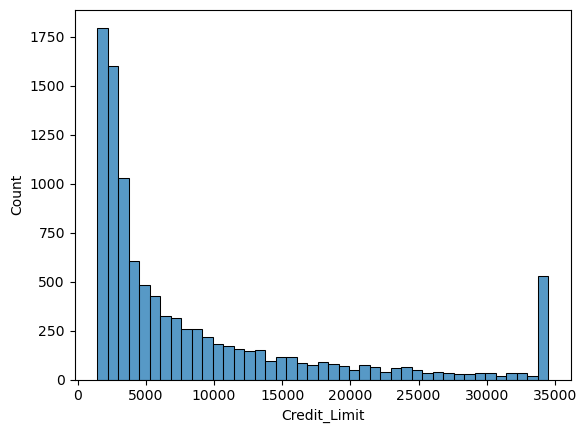

In [15]:
sns.histplot(x = 'Credit_Limit', data = df_train)

plt.show()

(20.0, 75.35)

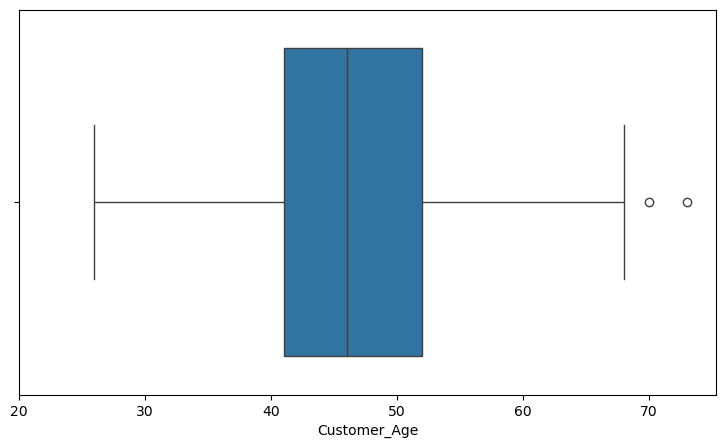

In [16]:
fig, ax = plt.subplots(figsize = (9, 5))
sns.boxplot(x= df_train.Customer_Age)
plt.xlim(20, None)

In [17]:
df_train.Card_Category.value_counts()

Card_Category
Blue        9436
Silver       555
Gold         116
Platinum      20
Name: count, dtype: int64

In [18]:
count = df_train.loc[df_train['Card_Category'] == 'Platinum', 'Gender'].value_counts()

counts = df_train.loc[df_train['Card_Category'] == 'Gold', 'Gender'].value_counts()

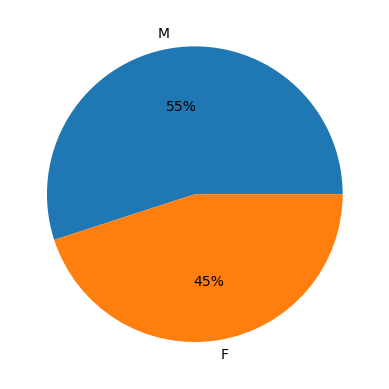

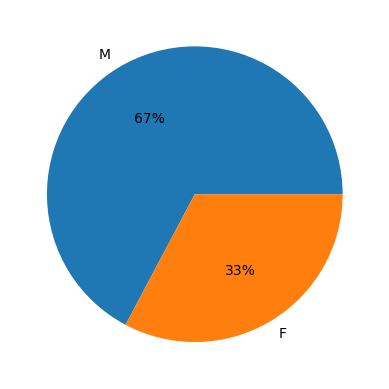

In [19]:
fig ,ax = plt.subplots()
plt.pie(x = count, labels = count.index, autopct = '%1.f%%')
plt.show()
plt.pie(x = counts, labels = counts.index, autopct = '%1.f%%')

plt.show()

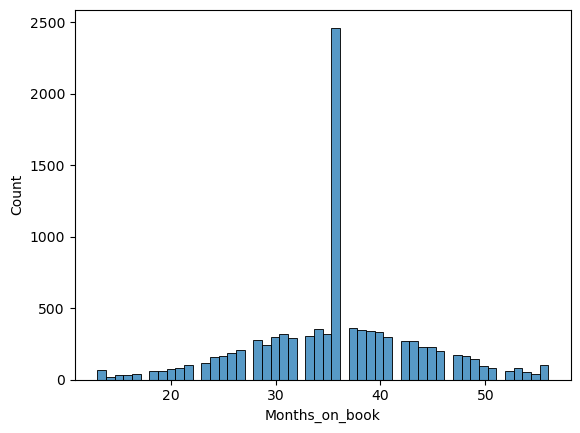

In [20]:
sns.histplot(x = 'Months_on_book', data = df_train)
plt.show()

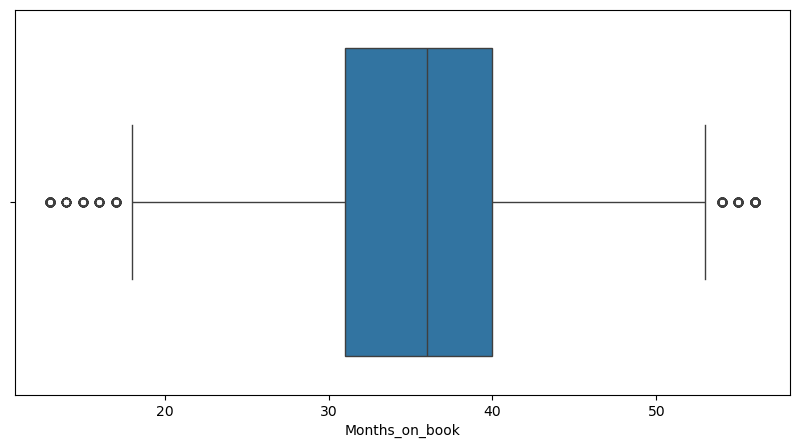

In [21]:
fig, ax = plt.subplots(figsize = (10,5))
sns.boxplot(x = 'Months_on_book', data = df_train)
plt.show()

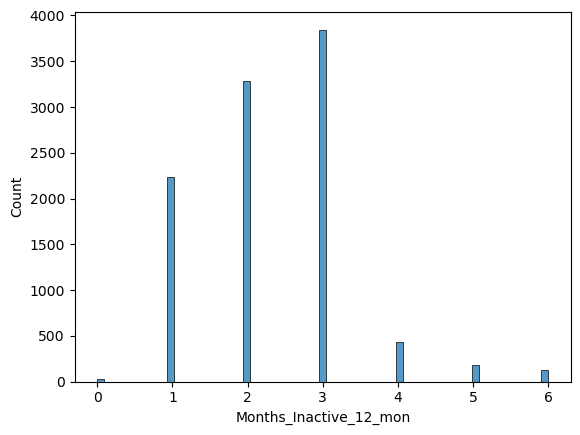

In [22]:
sns.histplot(x = 'Months_Inactive_12_mon', data = df_train)
plt.show()

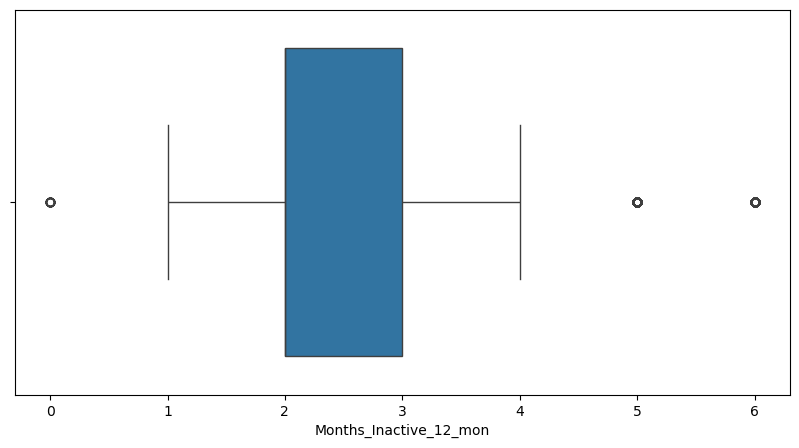

In [23]:
fig, ax = plt.subplots(figsize = (10,5))
sns.boxplot(x = 'Months_Inactive_12_mon', data = df_train)
plt.show()

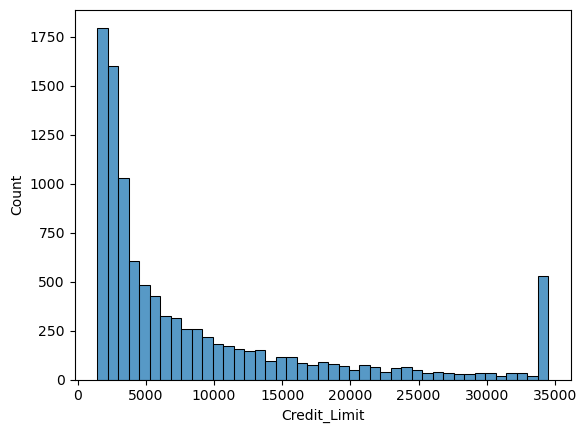

In [24]:
sns.histplot(x = 'Credit_Limit', data = df_train)
plt.show()

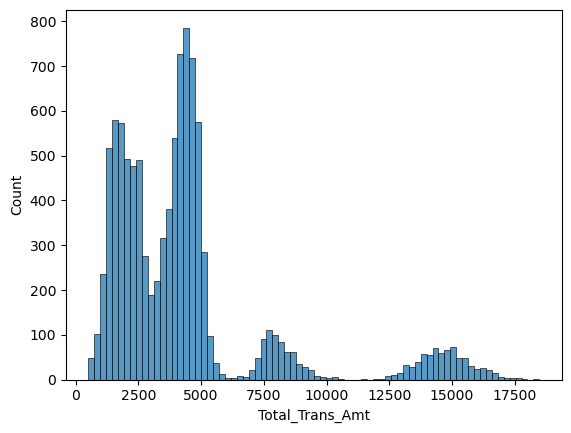

In [25]:
sns.histplot(x = 'Total_Trans_Amt', data = df_train)
plt.show()

In [26]:
tag = df_train['Attrition_Flag'].value_counts()
tag

Attrition_Flag
1    8500
0    1627
Name: count, dtype: int64

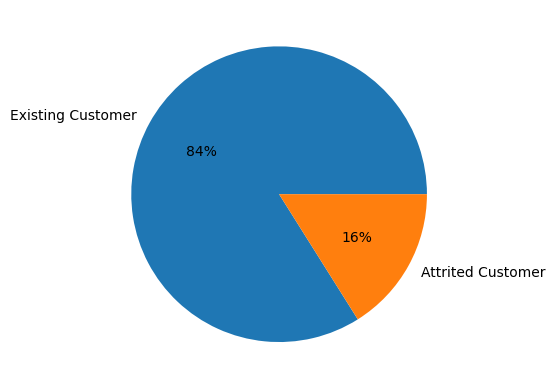

In [27]:
plt.pie(tag, labels = ['Existing Customer', 'Attrited Customer'], autopct = '%.0f%%')
plt.show()

In [28]:
df_train.Card_Category.value_counts()

Card_Category
Blue        9436
Silver       555
Gold         116
Platinum      20
Name: count, dtype: int64

In [29]:
num = df_train.select_dtypes(include = ['float64', 'int64']).columns

def cleaned(data, colss):
    for coli in cols:
        data[coli] = pd.to_numeric(data[coli], errors = 'coerce')
        return data


df_train = cleaned(df_train, num)
df_train.isna().sum()

Attrition_Flag              0
Customer_Age                0
Gender                      0
Dependent_count             0
Education_Level             0
Marital_Status              0
Income_Category             0
Card_Category               0
Months_on_book              0
Total_Relationship_Count    0
Months_Inactive_12_mon      0
Contacts_Count_12_mon       0
Credit_Limit                0
Total_Revolving_Bal         0
Avg_Open_To_Buy             0
Total_Amt_Chng_Q4_Q1        0
Total_Trans_Amt             0
Total_Trans_Ct              0
Total_Ct_Chng_Q4_Q1         0
Avg_Utilization_Ratio       0
dtype: int64

In [30]:
enc_inc = ['Less than $40K', '$40K - $60K', '$60K - $80K', '$80K - $120K', '$120K + ']
enc_edu = ['Uneducated', 'High School', 'College', 'Graduate', 'Post-Graduate', 'Doctorate']
enc_card = ['Blue', 'Silver', 'Gold', 'Platinum']

In [31]:
x = df_train.drop('Attrition_Flag', axis = 1)
y = df_train['Attrition_Flag']

In [32]:
enc = ['Education_Level', 'Income_Category', 'Card_Category']
enc

['Education_Level', 'Income_Category', 'Card_Category']

In [33]:
categorical_cols = x.select_dtypes(include = ['object']).columns
categorical_cols = [c for c in categorical_cols if c not in enc]

In [34]:
categorical_cols

['Gender', 'Marital_Status']

In [35]:
ordinal = Pipeline(steps=[
    ('ord', OrdinalEncoder(categories = [enc_edu, enc_inc, enc_card], handle_unknown = 'use_encoded_value', unknown_value = np.nan)),
    ('im', SimpleImputer(strategy = 'most_frequent'))
])


categorical = Pipeline(steps =[
    ('enc', OneHotEncoder(drop = 'first', sparse_output = False, handle_unknown = 'ignore')),
])



preprocessed = ColumnTransformer(transformers = [
    ('cat', categorical, categorical_cols),
    ('ordinal', ordinal, enc)
], verbose_feature_names_out = False, remainder = 'passthrough')

In [36]:
dele = pd.concat([x,y], axis = 1)
df_corr = dele.corr(numeric_only = True).sort_values(by = 'Attrition_Flag', ascending = False)
df_corr.drop('Attrition_Flag', inplace = True)

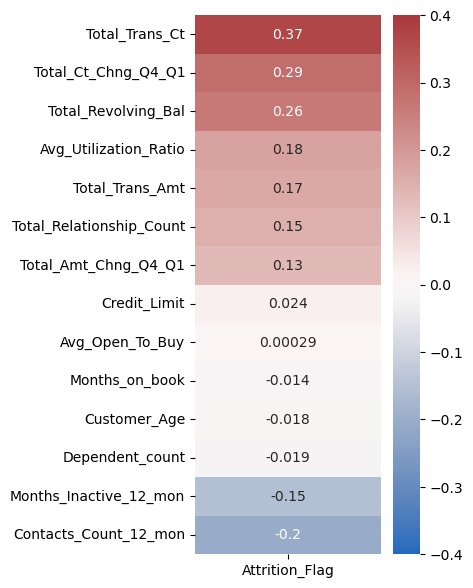

In [37]:
fig, ax = plt.subplots(figsize = (3, 7))
sns.heatmap(df_corr[['Attrition_Flag']], cmap = 'vlag', vmax = 0.4, vmin = -0.4, annot = True)
plt.show()

In [38]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 43, stratify = y)
preprocessed.set_output(transform = 'pandas')
x_train_sourced = preprocessed.fit_transform(x_train)
x_test_sourced = preprocessed.transform(x_test)

In [39]:
x_train_sourced

,Gender_M,Marital_Status_Married,Marital_Status_Single,Marital_Status_Unknown,Education_Level,Income_Category,Card_Category,Customer_Age,Dependent_count,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
7404,0.0,0.0,1.0,0.0,1.0,0.0,0.0,44,3,33,3,3,3,5362.0,1984,3378.0,0.664,3851,87,0.642,0.370
2051,1.0,0.0,0.0,0.0,2.0,1.0,0.0,30,2,22,3,3,4,3143.0,1075,2068.0,0.643,2510,57,0.629,0.342
3029,1.0,0.0,0.0,0.0,0.0,2.0,0.0,50,0,39,6,3,3,9474.0,1021,8453.0,0.557,3240,54,0.588,0.108
5624,1.0,0.0,1.0,0.0,3.0,3.0,0.0,41,5,28,3,2,0,2491.0,1979,512.0,0.629,1911,35,0.750,0.794
2016,1.0,0.0,1.0,0.0,3.0,1.0,0.0,31,2,36,3,2,4,6269.0,1169,5100.0,0.743,2221,57,0.727,0.186
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2524,0.0,0.0,1.0,0.0,3.0,0.0,0.0,35,3,17,6,1,1,2956.0,1823,1133.0,0.969,2144,58,0.812,0.617
1597,1.0,0.0,1.0,0.0,1.0,0.0,0.0,51,3,36,5,1,4,20741.0,2504,18237.0,0.800,1818,51,1.040,0.121
62,1.0,0.0,0.0,0.0,1.0,2.0,0.0,39,1,33,5,3,3,5926.0,1251,4675.0,0.944,1316,28,1.154,0.211
54,1.0,1.0,0.0,0.0,3.0,0.0,0.0,56,2,36,1,3,3,15769.0,0,15769.0,1.041,602,15,0.364,0.000


In [40]:
modelo = [('XGBoost Classifier', XGBClassifier(random_state = 43)),
          ('Decision Tree Classifier', DecisionTreeClassifier(random_state = 43)),
          ('Random Forest Classifier', RandomForestClassifier(random_state = 43)),
          ('Catboost Classifier', CatBoostClassifier(random_state = 43, verbose = 0))]


In [41]:
scored = {}
for cels, cel in modelo:
    score = cross_val_score(cel, x_train_sourced, y_train, cv = 5, scoring = 'f1') 
    scored[cels] = score

scored_df = pd.DataFrame(scored)

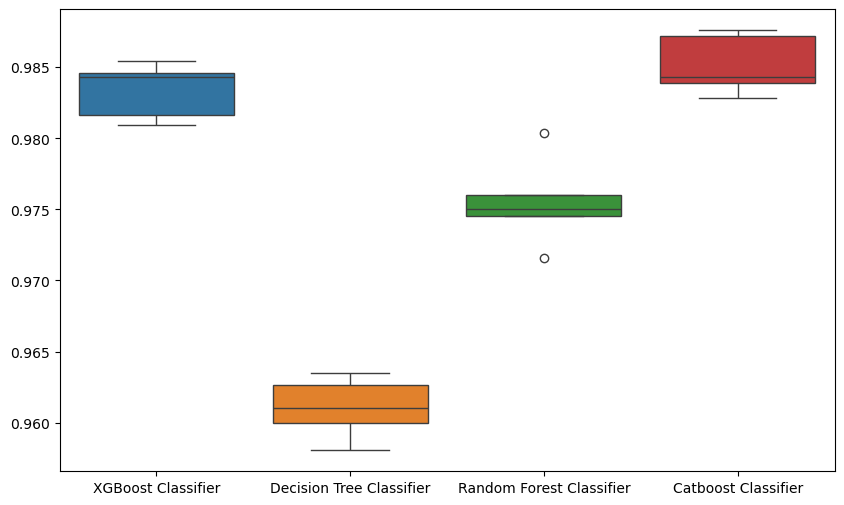

In [42]:
fig, ax = plt.subplots(figsize = (10, 6))
sns.boxplot(scored_df)
plt.show()

In [44]:
cat = CatBoostClassifier(random_state = 43, verbose = 0)
cat.fit(x_train_sourced, y_train)

print('Training Score', cat.score(x_train_sourced, y_train))
print('Testing Score', cat.score(x_test_sourced, y_test))

Training Score 0.9958029872855203
Testing Score 0.9758144126357354


In [45]:
y_churn = 1 - y_test
y_pred = cat.predict_proba(x_test_sourced)[:,0]

precision, recall, thresholds = precision_recall_curve(y_churn, y_pred)
ap = average_precision_score(y_churn, y_pred)
baseline = y_churn.mean()

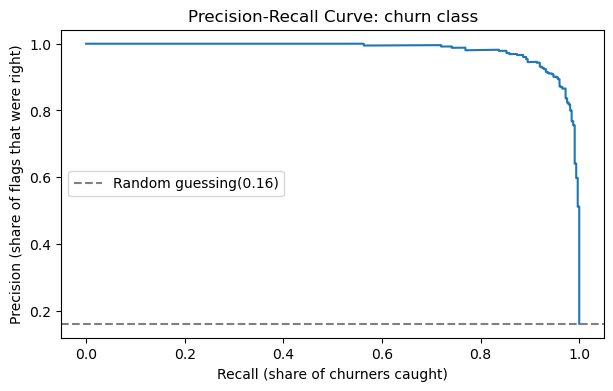

In [46]:
fig, ax = plt.subplots(figsize = (7, 4))
plt.plot(recall, precision)
plt.axhline(baseline, linestyle = '--', color = 'gray', label = f'Random guessing({baseline:.2f})')

plt.xlabel('Recall (share of churners caught)')
plt.ylabel('Precision (share of flags that were right)')
plt.title('Precision-Recall Curve: churn class')
plt.legend()
plt.show()